In [37]:
%matplotlib inline

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

### preprocessing

In [38]:
NOTEBOOK_DIR = os.path.dirname(os.path.abspath("__file__"))

In [39]:
df_raw = pd.read_csv(os.path.join(NOTEBOOK_DIR, "source_data", "olive_oils.csv"))

### Test/train split

In [40]:
X = df_raw.drop(columns=["Area", "Region"])
Y = df_raw["Region"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y,
                                                    test_size=0.3,
                                                    random_state=598,
                                                    stratify=Y)
display(f"X_train shape: {X_train.shape}")
display(f"X_test shape: {X_test.shape}")
display(f"Y_train shape: {Y_train.shape}")
display(f"Y_test shape: {Y_test.shape}")

'X_train shape: (400, 8)'

'X_test shape: (172, 8)'

'Y_train shape: (400,)'

'Y_test shape: (172,)'

In [41]:
display((Y_train == "Sardinia").mean())
display((Y_test == "Sardinia").mean())
(Y == "Sardinia").mean()

0.17

0.1744186046511628

0.17132867132867133

## Question a

In [42]:
lda_model = LinearDiscriminantAnalysis()
lda_model.fit(X_train, Y_train);

In [43]:
qda_model = QuadraticDiscriminantAnalysis()
qda_model.fit(X_train, Y_train);

In [44]:
lr_model = LogisticRegression(random_state=598, solver="newton-cholesky")
lr_model.fit(X_train, Y_train);

> Because of what I later found out to be perfect separability in the test set, I had to change the logistic-regression solver from the default "Limited-memory BFGS" to Newton-Cholesky to attain convergence.    

## Question b

Report the accuracy for all methods on both training and testing data sets, and prepare confusion matrices for the test predictions.  
Label the rows and columns by region, not by integer codes. Rows are the true region; columns are the predicted region.

In [45]:
Y_pred_train_1 = lda_model.predict(X_train)
Y_pred_train_2 = qda_model.predict(X_train)
Y_pred_train_3 = lr_model.predict(X_train)

In [46]:
display((Y_train == Y_pred_train_1).mean())
display((Y_train == Y_pred_train_2).mean())
display((Y_train == Y_pred_train_3).mean())

0.9875

1.0

1.0

In [47]:
Y_train.shape[0] - (Y_train == Y_pred_train_1).sum()

5

> Only 5 training errors

In [48]:
Y_pred_test_1 = lda_model.predict(X_test)
Y_pred_test_2 = qda_model.predict(X_test)
Y_pred_test_3 = lr_model.predict(X_test)

In [49]:
display((Y_test == Y_pred_test_1).mean())
display((Y_test == Y_pred_test_2).mean())
display((Y_test == Y_pred_test_3).mean())

1.0

1.0

1.0

> No test errors

> LDA made only 5 training errors, giving an accuracy of 99%  
All three classifiers (LDA, QDA, and Logistic Regression) had 0 errors on the test set.

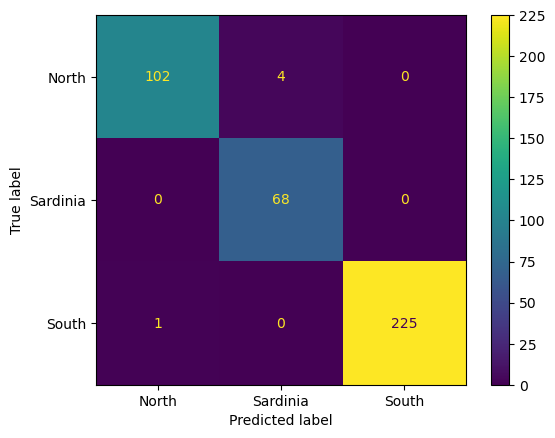

In [50]:
with plt.rc_context({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "text.color": "black",
    "axes.labelcolor": "black", "axes.edgecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
}):
   ConfusionMatrixDisplay.from_predictions(
      Y_train, Y_pred_train_1, labels=np.array(["North", "Sardinia", "South"]));

## Question c

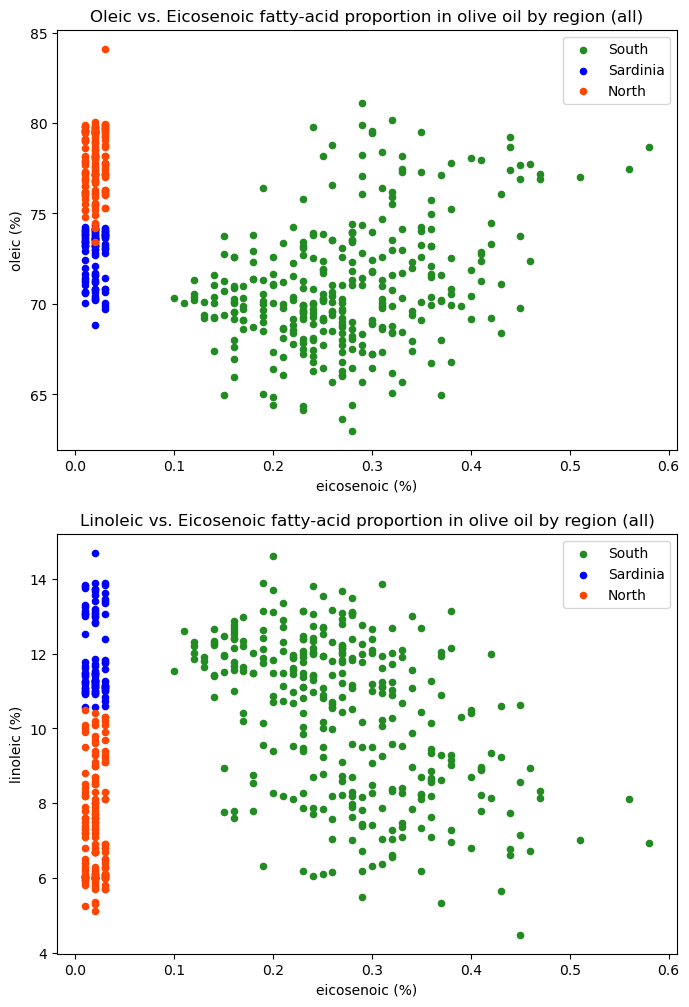

In [51]:
with plt.rc_context({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "text.color": "black",
    "axes.labelcolor": "black", "axes.edgecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
}):
    fig, ax = plt.subplots(2, 1)
    ax1 = ax[0]
    ax2 = ax[1]
    fig.set_size_inches(8, 12)
    (df_raw.loc[df_raw["Region"] == "South", ["eicosenoic", "oleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "oleic", color="forestgreen", ax=ax1)
    (df_raw.loc[df_raw["Region"] == "Sardinia", ["eicosenoic", "oleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "oleic", color="blue", ax=ax1)
    (df_raw.loc[df_raw["Region"] == "North", ["eicosenoic", "oleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "oleic", color="orangered", ax=ax1)
    ax1.set_xlabel("eicosenoic (%)")
    ax1.set_ylabel("oleic (%)")
    ax1.set_title("Oleic vs. Eicosenoic fatty-acid proportion in olive oil by region (all)");
    ax1.legend(["South", "Sardinia", "North"])


    (df_raw.loc[df_raw["Region"] == "South", ["eicosenoic", "linoleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "linoleic", color="forestgreen", ax=ax2)
    (df_raw.loc[df_raw["Region"] == "Sardinia", ["eicosenoic", "linoleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "linoleic", color="blue", ax=ax2)
    (df_raw.loc[df_raw["Region"] == "North", ["eicosenoic", "linoleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "linoleic", color="orangered", ax=ax2)
    ax2.set_xlabel("eicosenoic (%)")
    ax2.set_ylabel("linoleic (%)")
    ax2.set_title("Linoleic vs. Eicosenoic fatty-acid proportion in olive oil by region (all)");
    ax2.legend(["South", "Sardinia", "North"]);

> I chose to plot all the data (both train and test together) first.
 There appears to be a quite clear separation of the oils w.r.t. these fatty acids.  
 There is some slight overlap with South and North, but depending on the decision boundary constraints and the subsample, it's likely to be perfectly separable.

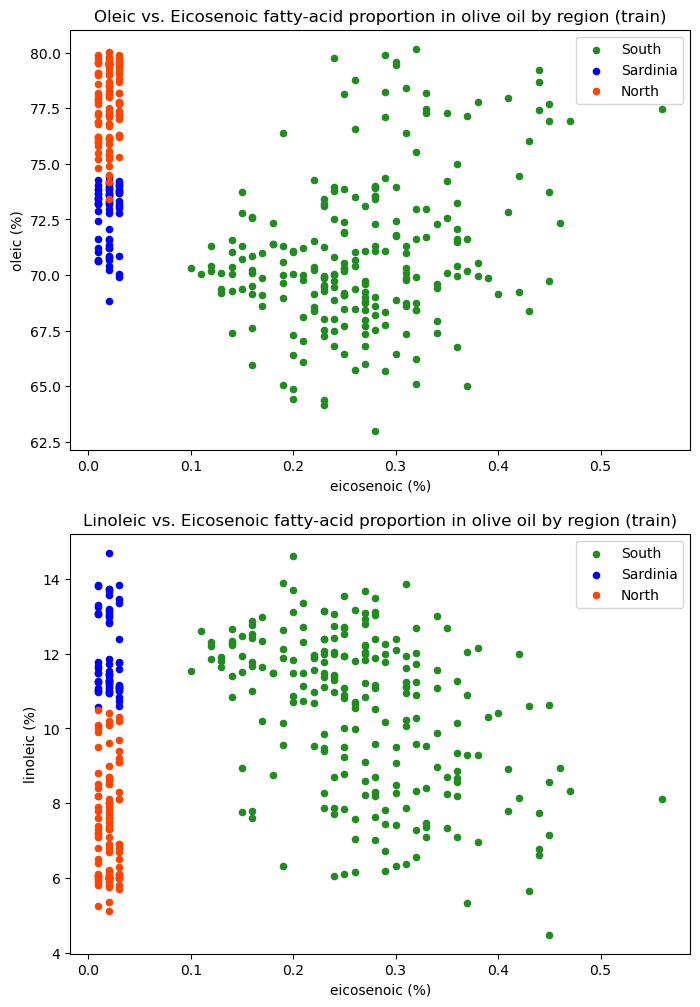

In [52]:
with plt.rc_context({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "text.color": "black",
    "axes.labelcolor": "black", "axes.edgecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
}):
    fig, ax = plt.subplots(2, 1)
    ax1 = ax[0]
    ax2 = ax[1]
    fig.set_size_inches(8, 12)
    (X_train.loc[Y_train == "South", ["eicosenoic", "oleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "oleic", color="forestgreen", ax=ax1)
    (X_train.loc[Y_train == "Sardinia", ["eicosenoic", "oleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "oleic", color="blue", ax=ax1)
    (X_train.loc[Y_train == "North", ["eicosenoic", "oleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "oleic", color="orangered", ax=ax1)
    ax1.set_xlabel("eicosenoic (%)")
    ax1.set_ylabel("oleic (%)")
    ax1.set_title("Oleic vs. Eicosenoic fatty-acid proportion in olive oil by region (train)");
    ax1.legend(["South", "Sardinia", "North"])

    (X_train.loc[Y_train == "South", ["eicosenoic", "linoleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "linoleic", color="forestgreen", ax=ax2)
    (X_train.loc[Y_train == "Sardinia", ["eicosenoic", "linoleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "linoleic", color="blue", ax=ax2)
    (X_train.loc[Y_train == "North", ["eicosenoic", "linoleic"]]/100).plot(kind="scatter", x = "eicosenoic", y = "linoleic", color="orangered", ax=ax2)
    ax2.set_xlabel("eicosenoic (%)")
    ax2.set_ylabel("linoleic (%)")
    ax2.set_title("Linoleic vs. Eicosenoic fatty-acid proportion in olive oil by region (train)");
    ax2.legend(["South", "Sardinia", "North"]);

> When plotting the training data, it's obvious North and South have some overlap along the "oleic axis" - the decision boundary cannot cleanly divide North from South there.
 The test set though, has perfect separation.

## Question d

> All three models perform flawlessly on the test set (given the 598 seed). The way the data were subsampled resulted in perfect separation.  
> LDA misclassified 5 observations in the training set, while QDA and logistic regression had perfect accuracy.

> For the training data (the only partition with any errors), the region classified most accurately is the South. The classifier only mis-labeled one oil that originates from the sourthern region (classifying it as having come from North), and it did not incorrectly group any other oils into the South group.
the LDA model mis-classified 4 oils from the North region, thinking they were from Sardinia.  
It did not make any mistakes the other way though (did not incorrectly classify any Sardinia oils as coming from the North)

> It appears that QDA provided the needed flexibility to fit the decision boundary around the nonlinear separation boundary that exists between North and Sardinia